In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Load the dataset**

In [ ]:
import pandas as pd

df = pd.read_csv("Housing.csv")

print(df.head())
print(df.shape)

      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  
(545, 13)


# **Check the dataset structure**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [ ]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

# **Checking the Missing Values**

In [ ]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [ ]:
df.isnull()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,False,False,False,False,False,False,False,False,False,False,False,False,False
541,False,False,False,False,False,False,False,False,False,False,False,False,False
542,False,False,False,False,False,False,False,False,False,False,False,False,False
543,False,False,False,False,False,False,False,False,False,False,False,False,False


# **Check Duplicate Rows**

In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
540,False
541,False
542,False
543,False


In [ ]:
df.duplicated().sum()

np.int64(0)

# **Check the DataTypes**

In [ ]:
df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,object
guestroom,object
basement,object
hotwaterheating,object
airconditioning,object


# **Check the unique values in Categorical Columns**

In [ ]:
categorical_columns = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]

for col in categorical_columns:
    print(col, df[col].unique())

mainroad ['yes' 'no']
guestroom ['no' 'yes']
basement ['no' 'yes']
hotwaterheating ['no' 'yes']
airconditioning ['yes' 'no']
prefarea ['yes' 'no']


standardize them: -> upper to lower

In [ ]:
for col in categorical_columns:
    df[col] = df[col].str.lower().str.strip()

# **Convert Yes/No into 1/0**

In [ ]:
mapping = {'yes': 1, 'no': 0}

for col in categorical_columns:
    df[col] = df[col].map(mapping)

In [ ]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,unfurnished
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,semi-furnished
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,unfurnished
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,furnished


In [ ]:
df['furnishingstatus'].unique()

array(['furnished', 'semi-furnished', 'unfurnished'], dtype=object)

In [ ]:
df['furnishingstatus'] = df['furnishingstatus'].map({
    'unfurnished': 0,
    'semi-furnished': 1,
    'furnished': 2
})

In [ ]:
print(df['furnishingstatus'].unique())

[2 1 0]


In [ ]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,2
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,2
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,2
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,0
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,1
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,0
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,2


# **Check the Numerical Values**

# describe() -> method

In [ ]:
df[['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus']].describe()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.858716,0.177982,0.350459,0.045872,0.315596,0.693578,0.234862,0.930275
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.348635,0.382849,0.477552,0.209399,0.465180,0.861586,0.424302,0.761373
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,2.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,2.000000


In [ ]:
print(df['bedrooms'].value_counts())
print(df['bathrooms'].value_counts())
print(df['mainroad'].value_counts())
print(df['parking'].value_counts())
print(df['prefarea'].value_counts())

bedrooms
3    300
2    136
4     95
5     10
6      2
1      2
Name: count, dtype: int64
bathrooms
1    401
2    133
3     10
4      1
Name: count, dtype: int64
mainroad
1    468
0     77
Name: count, dtype: int64
parking
0    299
1    126
2    108
3     12
Name: count, dtype: int64
prefarea
0    417
1    128
Name: count, dtype: int64


# **Info -> Method**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    int64
 6   guestroom         545 non-null    int64
 7   basement          545 non-null    int64
 8   hotwaterheating   545 non-null    int64
 9   airconditioning   545 non-null    int64
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    int64
 12  furnishingstatus  545 non-null    int64
dtypes: int64(13)
memory usage: 55.5 KB


# **Check Outliers**

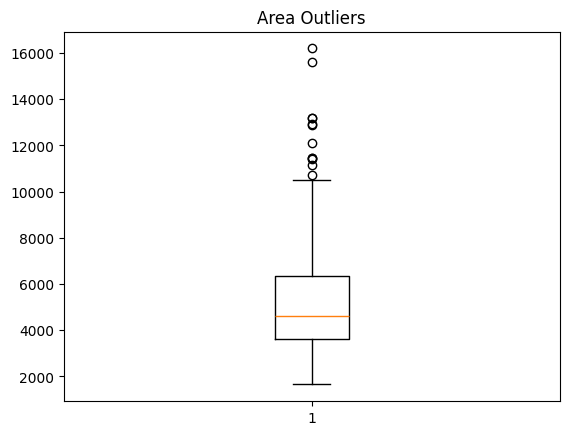

In [ ]:
import matplotlib.pyplot as plt

plt.boxplot(df['area'])
plt.title("Area Outliers")
plt.show()

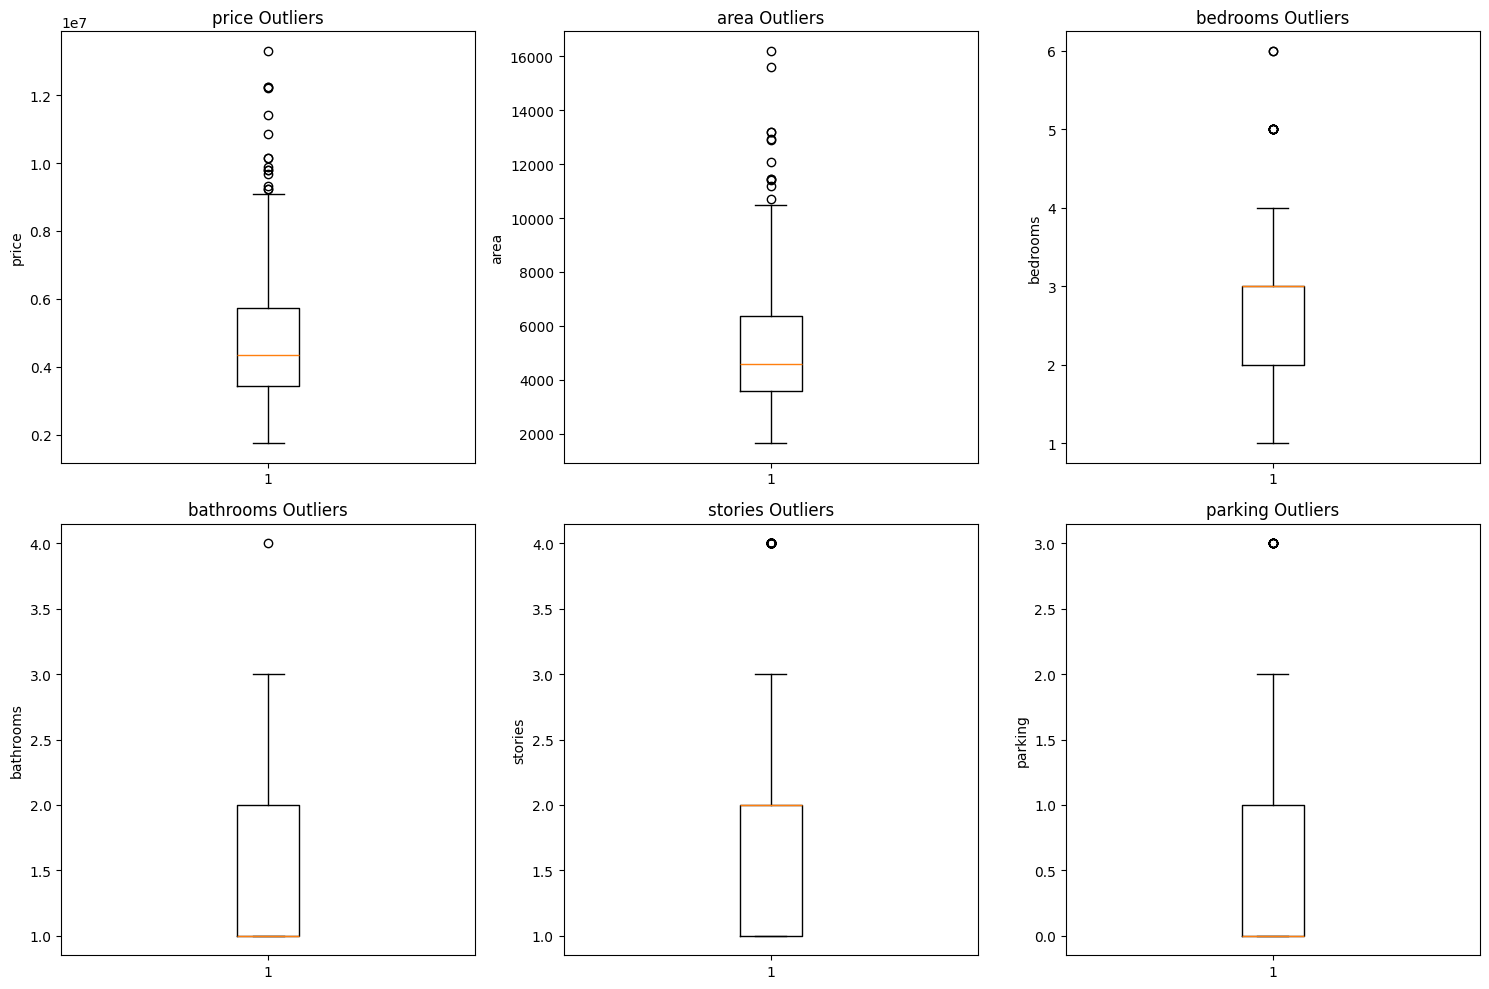

In [ ]:
columns = [
    'price', 'area', 'bedrooms', 'bathrooms', 'stories',
    'parking'
]

plt.figure(figsize=(15, 10))

for i, col in enumerate(columns, 1):
    plt.subplot(2, 3, i)
    plt.boxplot(df[col])
    plt.title(f'{col} Outliers')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

# **Find which columns have the outliers**

In [ ]:
numeric_columns = [
    'price', 'area', 'bedrooms',
    'bathrooms', 'stories', 'parking'
]

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

price: 15 outliers
area: 12 outliers
bedrooms: 12 outliers
bathrooms: 1 outliers
stories: 41 outliers
parking: 12 outliers


price       → valid expensive houses

area        → valid large houses

bedrooms    → 5 or 6 bedrooms are possible

bathrooms   → 4 bathrooms is possible

stories     → 4 stories is possible

parking     → 3 parking spaces is possible

In [ ]:
numeric_columns = [
    'price', 'area', 'bedrooms',
    'bathrooms', 'stories', 'parking'
]

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n===== {col} =====")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outlier values:")
    print(outliers[col].unique())


===== price =====
Lower limit: -35000.0
Upper limit: 9205000.0
Outlier values:
[13300000 12250000 12215000 11410000 10850000 10150000  9870000  9800000
  9681000  9310000  9240000]

===== area =====
Lower limit: -540.0
Upper limit: 10500.0
Outlier values:
[16200 13200 11440 11175 12090 15600 11460 11410 10700 12900 12944]

===== bedrooms =====
Lower limit: 0.5
Upper limit: 4.5
Outlier values:
[5 6]

===== bathrooms =====
Lower limit: -0.5
Upper limit: 3.5
Outlier values:
[4]

===== stories =====
Lower limit: -0.5
Upper limit: 3.5
Outlier values:
[4]

===== parking =====
Lower limit: -1.5
Upper limit: 2.5
Outlier values:
[3]


# **Keep Valid Outliers**

In [ ]:
# Keep all valid records, including valid outliers
df = df.copy()

print("Dataset shape:", df.shape)

Dataset shape: (545, 13)


# Select Features and Target column

In [ ]:
X = df[
    ['area',
     'bedrooms',
     'bathrooms',
     'mainroad',
     'basement']
]

y = df['price']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   area  bedrooms  bathrooms  mainroad  basement
0  7420         4          2         1         0
1  8960         4          4         1         0
2  9960         3          2         1         1
3  7500         4          2         1         1
4  7420         4          1         1         1

Target:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


# **Visualization**

**price distribution**

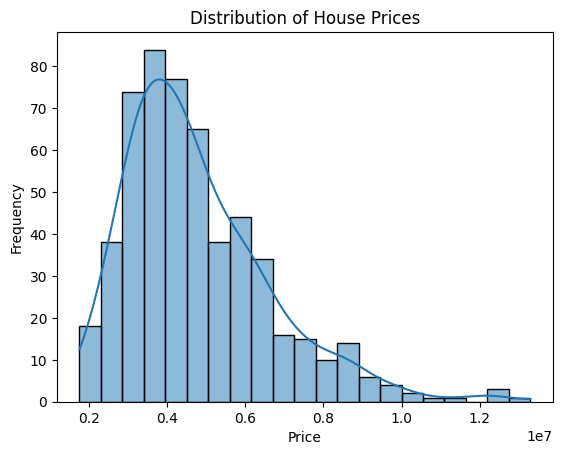

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['price'], kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

**Area vs Price**

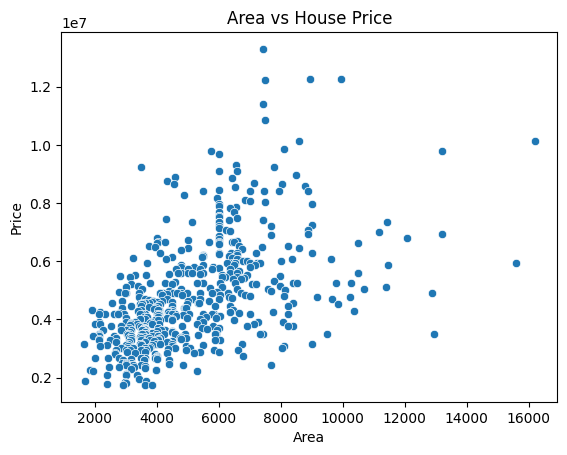

In [ ]:
sns.scatterplot(data=df, x='area', y='price')
plt.title("Area vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

**Bedrooms vs Price**

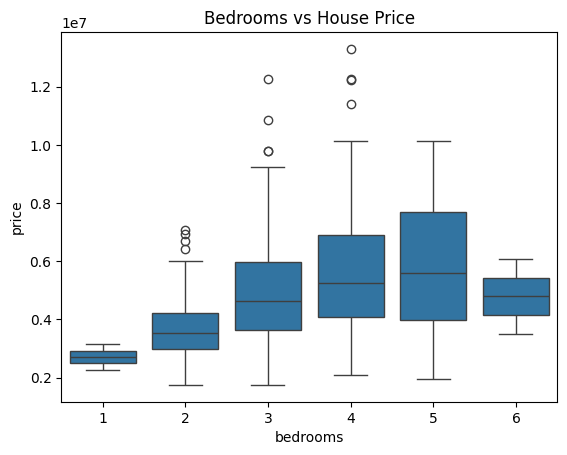

In [ ]:
sns.boxplot(data=df, x='bedrooms', y='price')
plt.title("Bedrooms vs House Price")
plt.show()

**Bathroom vs Price**

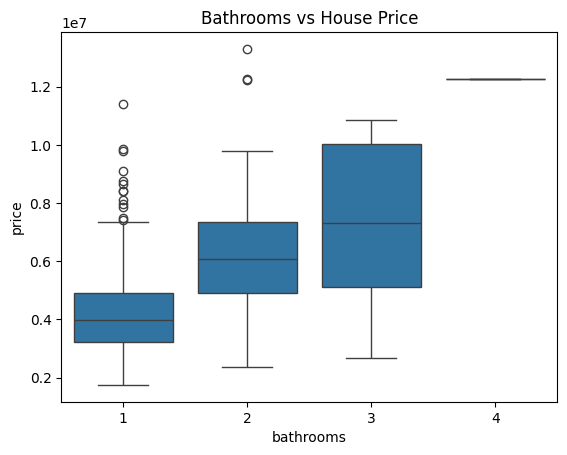

In [ ]:
sns.boxplot(data=df, x='bathrooms', y='price')
plt.title("Bathrooms vs House Price")
plt.show()

**MainRoad vs Price**

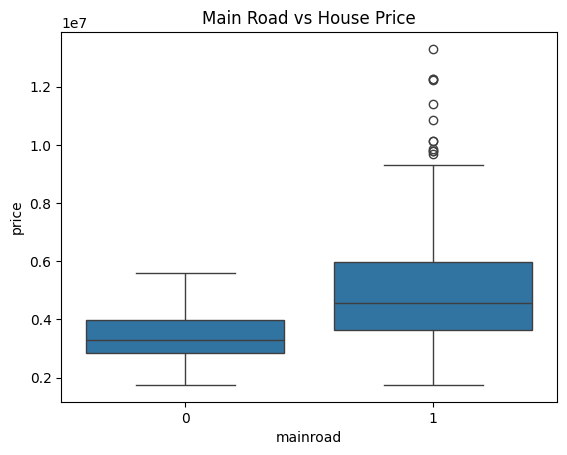

In [ ]:
sns.boxplot(data=df, x='mainroad', y='price')
plt.title("Main Road vs House Price")
plt.show()

**Basement vs Price**

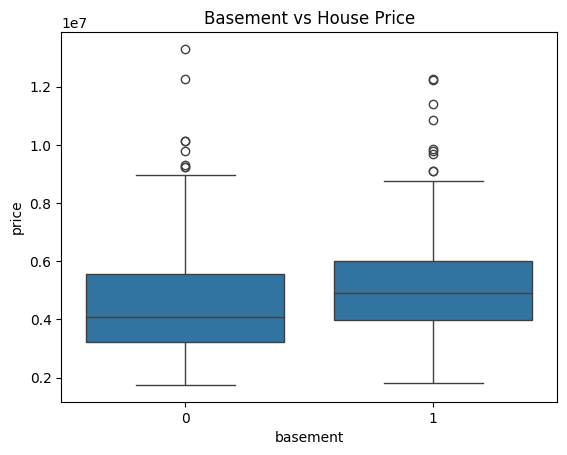

In [ ]:
sns.boxplot(data=df, x='basement', y='price')
plt.title("Basement vs House Price")
plt.show()

# **Correlation HeatMap**

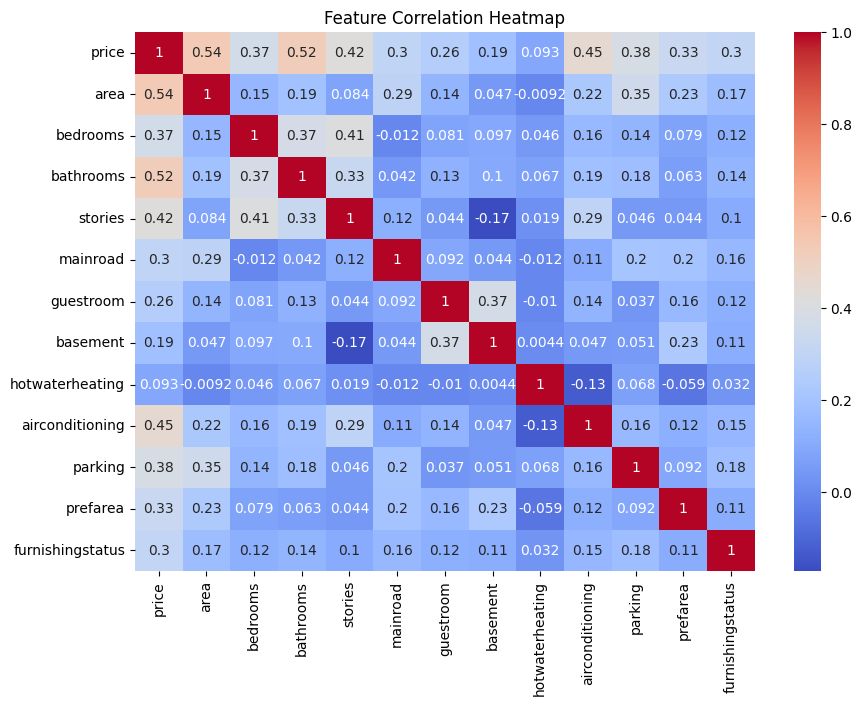

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Feature Correlation Heatmap")
plt.show()

# **Remove outliers from the numerical columns**

In [ ]:
numeric_columns = [
    'price',
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df = df[
        (df[col] >= lower_limit) &
        (df[col] <= upper_limit)
    ]

print("Dataset shape after removing outliers:")
print(df.shape)

Dataset shape after removing outliers:
(365, 13)


# **Check the outliers again**

In [ ]:
numeric_columns = [
    'price',
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"{col}: {len(outliers)} outliers")

price: 7 outliers
area: 5 outliers
bedrooms: 0 outliers
bathrooms: 0 outliers
stories: 0 outliers
parking: 0 outliers


# **Then recreate X and y**

In [ ]:
X = df[
    [
        'area',
        'bedrooms',
        'bathrooms',
        'mainroad',
        'basement'
    ]
]

y = df['price']

# **Do train/test split again**

80% → training

20% → testing

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# **Scale again**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# **ALGORITHMS**

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R² Score:", r2)
print("RMSE:", rmse)

R² Score: 0.41719275304674786
RMSE: 1115115.1557323944


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 840040.052026307
MSE : 1243481810544.0825
RMSE: 1115115.1557323944
R²  : 0.41719275304674786


In [ ]:
percentage_error = (abs(y_test - y_pred) / y_test) * 100

print(percentage_error.head(10))

358    12.692106
126     7.584550
90     37.115648
485    15.433192
178     3.507410
346    24.839565
205     9.701984
261    19.067384
302    23.178027
268     0.111368
Name: price, dtype: float64


In [ ]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np

np.random.seed(0)
X = np.random.rand(100, 2)
y = X[:, 0] + np.sin(6 * np.pi * X[:, 1])

mutual_info = mutual_info_regression(X, y)
print("Mutual Information for each feature:", mutual_info)

Mutual Information for each feature: [0.42283584 0.54090791]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

def evaluate_model(name, model, X_test_data, y_test_data):

    y_pred = model.predict(X_test_data)

    mae = mean_absolute_error(y_test_data, y_pred)
    mse = mean_squared_error(y_test_data, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_data, y_pred)

    print("=" * 50)
    print(name)
    print("=" * 50)
    print("MAE  :", mae)
    print("MSE  :", mse)
    print("RMSE :", rmse)
    print("R²   :", r2)

    return r2, rmse, mae

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# ==========================================
# 1. CREATE MODELS
# ==========================================

linear_model = LinearRegression()

ridge_model = Ridge(alpha=1.0)

lasso_model = Lasso(alpha=10000)

tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

extra_model = ExtraTreesRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)


# ==========================================
# 2. TRAIN MODELS
# ==========================================

linear_model.fit(X_train_scaled, y_train)

ridge_model.fit(X_train_scaled, y_train)

lasso_model.fit(X_train_scaled, y_train)

tree_model.fit(X_train, y_train)

rf_model.fit(X_train, y_train)

gb_model.fit(X_train, y_train)

extra_model.fit(X_train, y_train)


# ==========================================
# 3. EVALUATE MODELS
# ==========================================

models = {
    "Linear Regression": (linear_model, X_test_scaled),
    "Ridge Regression": (ridge_model, X_test_scaled),
    "Lasso Regression": (lasso_model, X_test_scaled),
    "Decision Tree": (tree_model, X_test),
    "Random Forest": (rf_model, X_test),
    "Gradient Boosting": (gb_model, X_test),
    "Extra Trees": (extra_model, X_test)
}


results = []


for name, (model, test_data) in models.items():

    y_pred = model.predict(test_data)

    r2 = r2_score(y_test, y_pred)

    accuracy = r2 * 100

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    results.append([
        name,
        accuracy,
        r2,
        mae,
        rmse
    ])


# ==========================================
# 4. CREATE RESULTS TABLE
# ==========================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy (%)",
        "R2 Score",
        "MAE",
        "RMSE"
    ]
)


# Sort by accuracy
results_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
)


# ==========================================
# 5. PRINT RESULTS
# ==========================================

print("\nMODEL PERFORMANCE")
print("=" * 80)

print(results_df.to_string(index=False))

print("\n" + "=" * 80)

best_model = results_df.iloc[0]

print("BEST MODEL :", best_model["Model"])
print("ACCURACY    :", round(best_model["Accuracy (%)"], 2), "%")
print("R2 SCORE    :", round(best_model["R2 Score"], 4))
print("MAE         :", round(best_model["MAE"], 2))
print("RMSE        :", round(best_model["RMSE"], 2))


MODEL PERFORMANCE
            Model  Accuracy (%)  R2 Score           MAE         RMSE
Gradient Boosting     46.925562  0.469256 802462.036124 1.064143e+06
Linear Regression     41.719275  0.417193 840040.052026 1.115115e+06
 Ridge Regression     41.687847  0.416878 840227.894489 1.115416e+06
    Random Forest     41.328036  0.413280 816065.428455 1.118852e+06
 Lasso Regression     41.265547  0.412655 843780.893915 1.119447e+06
      Extra Trees     40.700515  0.407005 832172.144337 1.124819e+06
    Decision Tree     38.539879  0.385399 886642.854906 1.145128e+06

BEST MODEL : Gradient Boosting
ACCURACY    : 46.93 %
R2 SCORE    : 0.4693
MAE         : 802462.04
RMSE        : 1064142.89


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

gb_model = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=2,
    min_samples_split=5,
    min_samples_leaf=2,
    subsample=0.8,
    random_state=42
)

gb_model.fit(X_train, y_train)

y_pred = gb_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Gradient Boosting Results")
print("-------------------------")
print("R² Score  :", r2)
print("Accuracy  :", r2 * 100, "%")
print("MAE       :", mae)
print("RMSE      :", rmse)

Gradient Boosting Results
-------------------------
R² Score  : 0.46318331977231475
Accuracy  : 46.31833197723147 %
MAE       : 820166.7637131219
RMSE      : 1070213.0631543961


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

parameters = [
    (100, 0.10, 2),
    (200, 0.05, 2),
    (300, 0.05, 2),
    (500, 0.03, 2),
    (200, 0.05, 3),
    (300, 0.03, 3),
    (500, 0.02, 3),
    (300, 0.05, 4),
]

best_score = -float("inf")
best_model = None
best_params = None

for n_estimators, learning_rate, max_depth in parameters:

    model = GradientBoostingRegressor(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        min_samples_split=5,
        min_samples_leaf=2,
        subsample=0.8,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)

    print(
        "Trees:", n_estimators,
        "| Learning Rate:", learning_rate,
        "| Depth:", max_depth,
        "| R²:", round(r2, 4),
        "| Accuracy:", round(r2 * 100, 2), "%"
    )

    if r2 > best_score:
        best_score = r2
        best_model = model
        best_params = (
            n_estimators,
            learning_rate,
            max_depth
        )

print("\n==============================")
print("BEST GRADIENT BOOSTING MODEL")
print("==============================")
print("Best Parameters:", best_params)
print("Best R²:", best_score)
print("Best Accuracy:", best_score * 100, "%")

Trees: 100 | Learning Rate: 0.1 | Depth: 2 | R²: 0.4341 | Accuracy: 43.41 %
Trees: 200 | Learning Rate: 0.05 | Depth: 2 | R²: 0.4576 | Accuracy: 45.76 %
Trees: 300 | Learning Rate: 0.05 | Depth: 2 | R²: 0.4667 | Accuracy: 46.67 %
Trees: 500 | Learning Rate: 0.03 | Depth: 2 | R²: 0.4632 | Accuracy: 46.32 %
Trees: 200 | Learning Rate: 0.05 | Depth: 3 | R²: 0.4624 | Accuracy: 46.24 %
Trees: 300 | Learning Rate: 0.03 | Depth: 3 | R²: 0.4749 | Accuracy: 47.49 %
Trees: 500 | Learning Rate: 0.02 | Depth: 3 | R²: 0.4717 | Accuracy: 47.17 %
Trees: 300 | Learning Rate: 0.05 | Depth: 4 | R²: 0.4686 | Accuracy: 46.86 %

BEST GRADIENT BOOSTING MODEL
Best Parameters: (300, 0.03, 3)
Best R²: 0.4749339222779535
Best Accuracy: 47.49339222779535 %


In [ ]:
# ============================================================
# SMART REAL ESTATE VALUATION - GEMINI AI CHATBOT
# SINGLE GOOGLE COLAB CELL
# ============================================================

!pip install -q -U google-genai


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import time
import textwrap
from google import genai


# ============================================================
# 2. API KEY
# ============================================================

API_KEY = "AQ.Ab8RN6J2vaIuw4ymPZhC5h4776PbHJuVS0-2LYcCRWFWMbpjkA"

client = genai.Client(
    api_key=API_KEY
)

print("=" * 70)
print("Gemini API Connected Successfully")
print("=" * 70)


# ============================================================
# 3. MODELS
# ============================================================

MODELS = [
    "gemini-2.5-flash-lite",
    "gemini-2.5-flash"
]


# ============================================================
# 4. PROJECT KNOWLEDGE
# ============================================================

PROJECT_CONTEXT = """

PROJECT: SMART REAL ESTATE VALUATION

This is a Machine Learning Regression project.

OBJECTIVE:
Predict house prices using property-related features.

DATASET:
545 rows
13 columns

TARGET:
price

FEATURES:
area
bedrooms
bathrooms
stories
mainroad
guestroom
basement
hotwaterheating
airconditioning
parking
prefarea
furnishingstatus


PREPROCESSING:
- Data cleaning
- Missing value checking
- Duplicate checking
- Categorical encoding
- Outlier detection
- Train-test split
- Feature scaling


TRAIN TEST SPLIT:
80% training
20% testing


OUTLIER METHOD:
IQR method.

Original dataset:
545 rows

After IQR filtering:
365 rows

IMPORTANT:
Some extreme real-estate values may be legitimate houses.
Therefore, outliers should not automatically be removed.


MODELS TESTED:

Linear Regression
R2 = 0.417193
Percentage Score = 41.72%
MAE = 840040.05
RMSE = 1115115.16


Ridge Regression
R2 = 0.416878
Percentage Score = 41.69%
MAE = 840227.89
RMSE = 1115416


Lasso Regression
R2 = 0.412655
Percentage Score = 41.27%
MAE = 843780.89
RMSE = 1119447


Decision Tree
R2 = 0.385399
Percentage Score = 38.54%
MAE = 886642.85
RMSE = 1145128


Random Forest
R2 = 0.413280
Percentage Score = 41.33%
MAE = 816065.43
RMSE = 1118852


Gradient Boosting
R2 = 0.469256
Percentage Score = 46.93%
MAE = 802462.04
RMSE = 1064143


Extra Trees
R2 = 0.407005
Percentage Score = 40.70%
MAE = 832172.14
RMSE = 1124819


GRADIENT BOOSTING HYPERPARAMETER TUNING:

100 trees, learning_rate=0.1, depth=2
R2 = 0.4341

200 trees, learning_rate=0.05, depth=2
R2 = 0.4576

300 trees, learning_rate=0.05, depth=2
R2 = 0.4667

500 trees, learning_rate=0.03, depth=2
R2 = 0.4632

200 trees, learning_rate=0.05, depth=3
R2 = 0.4624

300 trees, learning_rate=0.03, depth=3
R2 = 0.4749339223

500 trees, learning_rate=0.02, depth=3
R2 = 0.4717

300 trees, learning_rate=0.05, depth=4
R2 = 0.4686


CURRENT BEST MODEL:

Gradient Boosting Regressor

n_estimators = 300
learning_rate = 0.03
max_depth = 3

Best R2:
0.474934

Best percentage score:
47.49%


IMPORTANT:
This is a regression problem.

R2 is the appropriate evaluation metric.

R2 * 100 may be presented as a percentage score,
but it is technically not classification accuracy.


METRICS:

R2:
Higher is better.
Measures the amount of variation in price explained by the model.

MAE:
Mean Absolute Error.
Lower is better.

RMSE:
Root Mean Squared Error.
Lower is better.


EARLIER FEATURE SET:

area
bedrooms
bathrooms
mainroad
basement


RECOMMENDED FEATURE SET:

Use all available features:

area
bedrooms
bathrooms
stories
mainroad
guestroom
basement
hotwaterheating
airconditioning
parking
prefarea
furnishingstatus


RECOMMENDED IMPROVEMENTS:

1. Use all features.
2. Perform hyperparameter tuning.
3. Use cross-validation.
4. Analyze feature importance.
5. Compare original data with outlier-treated data.
6. Try Gradient Boosting, Random Forest, Extra Trees and XGBoost.
7. Perform feature engineering.


THE CHATBOT SHOULD ANSWER:

- Project aim
- Project objective
- Dataset
- Features
- Target variable
- Data preprocessing
- Outliers
- IQR
- Train-test split
- Feature scaling
- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Extra Trees
- XGBoost
- Hyperparameter tuning
- R2
- MAE
- RMSE
- Accuracy/percentage score
- Best model
- Model comparison
- Why performance is low
- How to improve the model
- Feature importance
- Project workflow
- Project explanation
- Viva questions
- Viva answers
- Interview questions
- Resume explanation
- Presentation explanation
- Python code
- Google Colab code
"""


# ============================================================
# 5. CHATBOT INSTRUCTIONS
# ============================================================

SYSTEM_INSTRUCTION = """

You are an AI assistant specifically for the
Smart Real Estate Valuation Machine Learning project.

Rules:

1. Answer using the project information provided.

2. Never invent project results.

3. Current best model:
Gradient Boosting Regressor.

4. Current best R2:
0.474934.

5. Current percentage score:
47.49%.

6. Explain that R2 is not technically classification accuracy.

7. If the user asks for code:
Give complete Google Colab-compatible code.

8. Define every variable before using it.

9. Use the project's actual feature names.

10. If the user asks for viva questions:
Give question and answer format.

11. If the user asks for interview explanation:
Give simple professional explanation.

12. If the user asks how to improve the model:
Recommend using all features, hyperparameter tuning,
cross-validation, feature engineering and careful
outlier treatment.

13. Do not claim that 47.49% is the final possible score.

14. Clearly distinguish actual results from recommendations.

15. Never reveal or repeat the API key.

16. Maintain conversation context.

17. For beginner questions, use simple language.

18. For technical questions, provide technical details.

19. If information is unavailable, say so instead
of inventing an answer.
"""


# ============================================================
# 6. CONVERSATION HISTORY
# ============================================================

history = []


# ============================================================
# 7. ASK GEMINI
# ============================================================

def ask_question(question):

    previous = ""

    for item in history[-8:]:

        previous += f"""

User:
{item["user"]}

Assistant:
{item["assistant"]}

"""


    prompt = f"""

{SYSTEM_INSTRUCTION}

============================================================
PROJECT INFORMATION
============================================================

{PROJECT_CONTEXT}

============================================================
PREVIOUS CONVERSATION
============================================================

{previous}

============================================================
USER QUESTION
============================================================

{question}

============================================================
ANSWER
============================================================

Answer specifically for the Smart Real Estate Valuation project.

If code is requested, provide complete runnable code.

If the user asks about the model result, use the actual
reported project results.

Do not invent values.
"""


    last_error = None


    # Try available models
    for model in MODELS:

        for attempt in range(2):

            try:

                response = client.models.generate_content(
                    model=model,
                    contents=prompt
                )

                answer = response.text

                history.append({
                    "user": question,
                    "assistant": answer
                })

                return answer


            except Exception as e:

                last_error = e

                time.sleep(3)


    return f"""
Gemini is temporarily unavailable.

Please try the question again after a short time.

Error:
{last_error}
"""


# ============================================================
# 8. DISPLAY ANSWER
# ============================================================

def display_answer(answer):

    print()
    print("=" * 80)
    print("SMART REAL ESTATE AI ASSISTANT")
    print("=" * 80)
    print()

    print(answer)

    print()
    print("=" * 80)


# ============================================================
# 9. START CHATBOT
# ============================================================

print()
print("=" * 80)
print("SMART REAL ESTATE VALUATION - AI CHATBOT")
print("=" * 80)

print()
print("Ask anything about your project.")

print()
print("Examples:")
print("• What is the aim of my project?")
print("• What is the best algorithm?")
print("• Why is my score only 47.49%?")
print("• Explain Gradient Boosting.")
print("• Explain my outliers.")
print("• Give me code to improve the model.")
print("• Explain R2, MAE and RMSE.")
print("• Give me 20 viva questions.")
print("• Explain my project for an interview.")
print("• Give me the project workflow.")
print()

print("Type 'exit' to stop.")
print("Type 'clear' to clear conversation.")

print()
print("=" * 80)


# ============================================================
# 10. CHAT LOOP
# ============================================================

while True:

    question = input("\nYou: ").strip()


    if question == "":
        continue


    if question.lower() in ["exit", "quit", "stop"]:

        print("\nChatbot: Goodbye!")
        break


    if question.lower() == "clear":

        history.clear()

        print("\nConversation history cleared.")

        continue


    answer = ask_question(question)

    display_answer(answer)

Gemini API Connected Successfully

SMART REAL ESTATE VALUATION - AI CHATBOT

Ask anything about your project.

Examples:
• What is the aim of my project?
• What is the best algorithm?
• Why is my score only 47.49%?
• Explain Gradient Boosting.
• Explain my outliers.
• Give me code to improve the model.
• Explain R2, MAE and RMSE.
• Give me 20 viva questions.
• Explain my project for an interview.
• Give me the project workflow.

Type 'exit' to stop.
Type 'clear' to clear conversation.


You: Explain R2, MAE and RMSE.

SMART REAL ESTATE AI ASSISTANT

Certainly! In the Smart Real Estate Valuation project, we use several metrics to evaluate how well our machine learning models predict house prices. Here's an explanation of R2, MAE, and RMSE:

### R2 (Coefficient of Determination)

*   **What it is:** R2, or the Coefficient of Determination, is a key metric for regression problems like predicting house prices. It measures the proportion of the variance in the dependent variable (house `pri

KeyboardInterrupt: Interrupted by user

In [ ]:
# ============================================================
# SMART REAL ESTATE PRICE PREDICTION CHATBOT
# GEMINI + DATASET + GRADIENT BOOSTING
# SINGLE GOOGLE COLAB CELL
# ============================================================

!pip install -q -U google-genai scikit-learn pandas numpy


# ============================================================
# IMPORTS
# ============================================================

import os
import re
import time
import pandas as pd
import numpy as np

from google import genai

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


# ============================================================
# GEMINI API
# ============================================================

# IMPORTANT:
# Put your NEW / ROTATED Gemini API key here.
# Do not use a key that has already been exposed.

API_KEY = "AQ.Ab8RN6J2vaIuw4ymPZhC5h4776PbHJuVS0-2LYcCRWFWMbpjkA"

client = genai.Client(
    api_key=API_KEY
)

GEMINI_MODEL = "gemini-2.5-flash"


# ============================================================
# LOAD DATASET
# ============================================================

print("=" * 70)
print("SMART REAL ESTATE PRICE PREDICTION CHATBOT")
print("=" * 70)

print("\nUpload your Housing.csv file")

from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("\nDataset loaded successfully!")

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])


# ============================================================
# CLEAN COLUMN NAMES
# ============================================================

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)


# ============================================================
# CONVERT CATEGORICAL VALUES
# ============================================================

binary_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for col in binary_columns:

    if col in df.columns:

        df[col] = (
            df[col]
            .astype(str)
            .str.lower()
            .map({
                "yes": 1,
                "no": 0
            })
        )


# ============================================================
# FURNISHING STATUS
# ============================================================

if "furnishingstatus" in df.columns:

    df["furnishingstatus"] = (
        df["furnishingstatus"]
        .astype(str)
        .str.lower()
        .map({
            "unfurnished": 0,
            "semi-furnished": 1,
            "furnished": 2
        })
    )


# ============================================================
# REMOVE MISSING VALUES
# ============================================================

df = df.dropna().copy()


# ============================================================
# FEATURES USED BY YOUR CURRENT MODEL
# ============================================================

FEATURES = [
    "area",
    "bedrooms",
    "bathrooms",
    "mainroad",
    "basement"
]

TARGET = "price"


# ============================================================
# CHECK FEATURES
# ============================================================

for col in FEATURES + [TARGET]:

    if col not in df.columns:

        raise ValueError(
            f"Column '{col}' is missing from dataset."
        )


# ============================================================
# TRAIN GRADIENT BOOSTING MODEL
# ============================================================

X = df[FEATURES].copy()

y = df[TARGET].copy()


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    subsample=0.8,
    random_state=42
)


model.fit(
    X_train,
    y_train
)


# ============================================================
# MODEL EVALUATION
# ============================================================

y_pred = model.predict(X_test)

r2 = r2_score(
    y_test,
    y_pred
)

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)


print("\nModel trained successfully!")

print("\nGradient Boosting R2:")
print(round(r2, 4))

print("Model Score:")
print(round(r2 * 100, 2), "%")


# ============================================================
# EXTRACT HOUSE REQUIREMENTS
# ============================================================

def extract_requirements(question):

    q = question.lower()

    values = {
        "area": None,
        "bedrooms": None,
        "bathrooms": None,
        "mainroad": None,
        "basement": None
    }


    # --------------------------------------------------------
    # AREA
    # --------------------------------------------------------

    area_patterns = [

        r'(\d+(?:\.\d+)?)\s*(?:sq\.?\s*ft|sqft|square\s*feet)',

        r'area\s*(?:is|=|:)?\s*(\d+(?:\.\d+)?)',

        r'(\d+(?:\.\d+)?)\s*sq'
    ]


    for pattern in area_patterns:

        match = re.search(
            pattern,
            q
        )

        if match:

            values["area"] = float(
                match.group(1)
            )

            break


    # --------------------------------------------------------
    # BEDROOMS
    # --------------------------------------------------------

    bedroom_patterns = [

        r'(\d+)\s*bedrooms?',

        r'bedrooms?\s*(?:is|=|:)?\s*(\d+)',

        r'(\d+)\s*bhk',

        r'(\d+)\s*bed'
    ]


    for pattern in bedroom_patterns:

        match = re.search(
            pattern,
            q
        )

        if match:

            values["bedrooms"] = int(
                match.group(1)
            )

            break


    # --------------------------------------------------------
    # BATHROOMS
    # --------------------------------------------------------

    bathroom_patterns = [

        r'(\d+)\s*bathrooms?',

        r'bathrooms?\s*(?:is|=|:)?\s*(\d+)',

        r'(\d+)\s*bath'
    ]


    for pattern in bathroom_patterns:

        match = re.search(
            pattern,
            q
        )

        if match:

            values["bathrooms"] = int(
                match.group(1)
            )

            break


    # --------------------------------------------------------
    # MAIN ROAD
    # --------------------------------------------------------

    if re.search(
        r'(main\s*road|mainroad).*(yes|available|connected)',
        q
    ):

        values["mainroad"] = 1

    elif re.search(
        r'(main\s*road|mainroad).*(no|not)',
        q
    ):

        values["mainroad"] = 0

    elif (
        "on main road" in q
        or "near main road" in q
    ):

        values["mainroad"] = 1


    # --------------------------------------------------------
    # BASEMENT
    # --------------------------------------------------------

    if (
        "with basement" in q
        or "basement yes" in q
        or "basement available" in q
        or "has basement" in q
    ):

        values["basement"] = 1

    elif (
        "without basement" in q
        or "no basement" in q
        or "basement no" in q
    ):

        values["basement"] = 0


    return values


# ============================================================
# FIND COMPARABLE HOUSES
# ============================================================

def comparable_price(requirements):

    filtered = df.copy()


    # --------------------------------------------------------
    # FILTER BEDROOMS
    # --------------------------------------------------------

    if requirements["bedrooms"] is not None:

        filtered = filtered[
            filtered["bedrooms"]
            == requirements["bedrooms"]
        ]


    # --------------------------------------------------------
    # FILTER BATHROOMS
    # --------------------------------------------------------

    if requirements["bathrooms"] is not None:

        filtered = filtered[
            filtered["bathrooms"]
            == requirements["bathrooms"]
        ]


    # --------------------------------------------------------
    # FILTER MAIN ROAD
    # --------------------------------------------------------

    if requirements["mainroad"] is not None:

        filtered = filtered[
            filtered["mainroad"]
            == requirements["mainroad"]
        ]


    # --------------------------------------------------------
    # FILTER BASEMENT
    # --------------------------------------------------------

    if requirements["basement"] is not None:

        filtered = filtered[
            filtered["basement"]
            == requirements["basement"]
        ]


    # --------------------------------------------------------
    # AREA
    # --------------------------------------------------------

    if requirements["area"] is not None:

        area = requirements["area"]

        # Select houses close to requested area

        tolerance = area * 0.20

        area_filtered = filtered[
            (
                filtered["area"]
                >= area - tolerance
            )
            &
            (
                filtered["area"]
                <= area + tolerance
            )
        ]

        if len(area_filtered) > 0:

            filtered = area_filtered


    return filtered


# ============================================================
# PREDICT USING ML MODEL
# ============================================================

def ml_prediction(requirements):

    # We can only use ML prediction when all
    # five model features are available.

    missing = []

    for feature in FEATURES:

        if requirements[feature] is None:

            missing.append(feature)


    if missing:

        return None


    input_data = pd.DataFrame(
        [[
            requirements["area"],
            requirements["bedrooms"],
            requirements["bathrooms"],
            requirements["mainroad"],
            requirements["basement"]
        ]],
        columns=FEATURES
    )


    prediction = model.predict(
        input_data
    )[0]


    return prediction


# ============================================================
# FORMAT PRICE
# ============================================================

def format_price(price):

    return f"₹{price:,.0f}"


# ============================================================
# NATURAL LANGUAGE RESPONSE
# ============================================================

def generate_response(
    question,
    requirements,
    prediction,
    comparable
):

    # --------------------------------------------------------
    # ML PREDICTION AVAILABLE
    # --------------------------------------------------------

    if prediction is not None:

        prompt = f"""

The user asked:

{question}

The trained Gradient Boosting ML model predicted:

{format_price(prediction)}

Input used by the model:

{requirements}

Model R2:
{r2:.4f}

Write a short, clear answer.

Tell the user the predicted house price.

Say that it is a machine-learning estimate,
not a guaranteed market price.

Do not change the predicted price.

Do not invent additional values.

Do not discuss project theory unless necessary.
"""

        response = client.models.generate_content(
            model=GEMINI_MODEL,
            contents=prompt
        )

        return response.text


    # --------------------------------------------------------
    # ONLY PARTIAL INFORMATION
    # --------------------------------------------------------

    if len(comparable) > 0:

        average_price = comparable["price"].mean()

        median_price = comparable["price"].median()

        minimum_price = comparable["price"].min()

        maximum_price = comparable["price"].max()

        count = len(comparable)


        prompt = f"""

The user asked:

{question}

The user provided:

{requirements}

The dataset contains {count} comparable houses.

Comparable house price statistics:

Average price:
{format_price(average_price)}

Median price:
{format_price(median_price)}

Minimum price:
{format_price(minimum_price)}

Maximum price:
{format_price(maximum_price)}

Give a concise answer.

If the user provided only bedrooms or partial requirements,
explain that this is a dataset-based estimate because
the trained ML model requires additional features.

Use the dataset statistics above.

Do not invent prices.

Recommend that the user provide area, bathrooms,
mainroad and basement for a model prediction.

Do not discuss unrelated project theory.
"""

        response = client.models.generate_content(
            model=GEMINI_MODEL,
            contents=prompt
        )

        return response.text


    # --------------------------------------------------------
    # NO COMPARABLE HOUSES
    # --------------------------------------------------------

    prompt = f"""

The user asked:

{question}

Their requirements are:

{requirements}

There are no sufficiently matching houses in the dataset.

Explain that the dataset does not contain enough
matching examples to provide a reliable dataset-based
estimate.

Ask the user for more flexible requirements.

Do not invent a price.
"""

    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt
    )

    return response.text


# ============================================================
# CHATBOT
# ============================================================

def chatbot(question):

    requirements = extract_requirements(
        question
    )


    # --------------------------------------------------------
    # CHECK IF HOUSE PRICE QUESTION
    # --------------------------------------------------------

    price_words = [
        "price",
        "cost",
        "worth",
        "how much",
        "predict",
        "prediction",
        "valuation"
    ]

    is_price_question = any(
        word in question.lower()
        for word in price_words
    )


    if is_price_question:

        # --------------------------------------------
        # FIRST TRY ACTUAL ML PREDICTION
        # --------------------------------------------

        prediction = ml_prediction(
            requirements
        )


        # --------------------------------------------
        # IF INCOMPLETE, FIND SIMILAR HOUSES
        # --------------------------------------------

        comparable = comparable_price(
            requirements
        )


        answer = generate_response(
            question,
            requirements,
            prediction,
            comparable
        )


        return answer


    # ========================================================
    # NON-PRICE QUESTION
    # ========================================================

    prompt = f"""

You are a Smart Real Estate Valuation chatbot.

The user asked:

{question}

Answer naturally and briefly.

If the user is asking about a house,
help them with house-price-related information.

If the user asks for a price prediction,
use the ML prediction system.

Do not invent house prices.

Do not provide a list of example questions.

Do not display chatbot instructions.

Do not discuss unrelated topics.
"""


    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt
    )


    return response.text


# ============================================================
# START CHATBOT
# ============================================================

print()
print("=" * 70)
print("CHATBOT READY")
print("=" * 70)

print()
print("Ask your house-price question.")

print()
print("Example:")
print(
    "I need 3 bedrooms, what is the price?"
)

print()
print("Type 'exit' to stop.")

print()
print("=" * 70)


# ============================================================
# CHAT LOOP
# ============================================================

while True:

    question = input("\nYou: ").strip()


    if not question:
        continue


    if question.lower() in [
        "exit",
        "quit",
        "stop"
    ]:

        print("\nGoodbye!")
        break


    try:

        answer = chatbot(
            question
        )


        print()
        print("=" * 80)
        print("SMART REAL ESTATE AI")
        print("=" * 80)
        print()
        print(answer)
        print()
        print("=" * 80)


    except Exception as e:

        print()
        print("Something went wrong:")
        print(e)

SMART REAL ESTATE PRICE PREDICTION CHATBOT

Upload your Housing.csv file


Saving Housing.csv to Housing (3).csv

Dataset loaded successfully!
Rows    : 545
Columns : 13

Model trained successfully!

Gradient Boosting R2:
0.492
Model Score:
49.2 %

CHATBOT READY

Ask your house-price question.

Example:
I need 3 bedrooms, what is the price?

Type 'exit' to stop.


You: I need 3 bedrooms, what is the price?

SMART REAL ESTATE AI

Based on the dataset of 300 comparable houses, the prices for a 3-bedroom house can vary significantly.

As you've only specified the number of bedrooms, a precise ML model prediction is not possible at this time. The trained ML model requires additional features such as `area`, `bathrooms`, `mainroad`, and `basement` for a more accurate estimate.

However, based on the overall dataset statistics:
*   **Average price:** ₹4,954,598
*   **Median price:** ₹4,620,000
*   **Price range:** ₹1,750,000 to ₹12,250,000

To get a more accurate model prediction for a 3-bedroom house, please provide additional details like `area`, `bathrooms`, `ma

KeyboardInterrupt: Interrupted by user